# 02 · Modelo de rentabilidades

Calibración y validación de los generadores de `pension_mc.returns` con las rentabilidades reales mensuales de **Protección** (feb-2016 a sep-2026):

1. **Bootstrap estacionario**: remuestrea bloques de meses históricos de largo aleatorio.
2. **t multivariada**: log-rentabilidades i.i.d. con colas gruesas.
3. **Escenarios deterministas**: percentiles de la rentabilidad anualizada simulada.

Más la trayectoria de **multifondos por defecto** según la edad (Decreto 2555 de 2010).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from statsmodels.tsa.stattools import acf

from pension_mc import returns as R

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
AZUL = {"150": "#b7d3f6", "250": "#86b6ef", "450": "#2a78d6", "650": "#104281"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "legend.frameon": False,
    "lines.linewidth": 2, "figure.figsize": (9, 4.2), "figure.dpi": 110, "font.size": 10,
})
NOMBRE = {"mayor_riesgo": "Mayor riesgo", "moderado": "Moderado", "conservador": "Conservador",
          "retiro_programado": "Retiro programado"}
pct = lambda d=1: mtick.PercentFormatter(1, decimals=d)

N_SIMS, SEED = 10_000, 2026
hist = R.historico("Protección")
x = np.log1p(hist.to_numpy())
print(f"{len(hist)} meses: {hist.index.min():%Y-%m} a {hist.index.max():%Y-%m}")

128 meses: 2016-02 a 2026-09


## 1. Calibración

In [2]:
calib = pd.DataFrame({
    "media_real_anual": np.expm1(x.mean(axis=0) * 12),
    "error_estandar_media": x.std(axis=0, ddof=1) * 12 / np.sqrt(len(x)),
    "volatilidad_anual": x.std(axis=0, ddof=1) * np.sqrt(12),
    "curtosis_exceso": pd.DataFrame(x).kurt().to_numpy(),
    "acf_rezago_1": [acf(x[:, j], nlags=1)[1] for j in range(x.shape[1])],
    "largo_bloque_optimo": [R.largo_bloque_optimo(x[:, j]) for j in range(x.shape[1])],
}, index=[NOMBRE[f] for f in hist.columns])
nu = R.ajustar_nu(x)
print(f"Grados de libertad de la t multivariada (MV perfilada): ν = {nu:g}")
calib.style.format({"media_real_anual": "{:.2%}", "error_estandar_media": "{:.2%}", "volatilidad_anual": "{:.2%}",
                    "curtosis_exceso": "{:.1f}", "acf_rezago_1": "{:.2f}", "largo_bloque_optimo": "{:.1f}"})

Grados de libertad de la t multivariada (MV perfilada): ν = 4


,media_real_anual,error_estandar_media,volatilidad_anual,curtosis_exceso,acf_rezago_1,largo_bloque_optimo
Mayor riesgo,4.10%,2.71%,8.86%,9.0,0.02,1.0
Moderado,3.71%,2.06%,6.71%,2.2,0.08,1.3
Conservador,2.33%,1.80%,5.88%,1.7,0.13,1.8
Retiro programado,2.82%,1.93%,6.30%,0.9,0.09,1.5


- **Largo de bloque ≈ 1–2 meses:** la autocorrelación mensual es débil, así que el bootstrap queda cerca de un remuestreo de meses sueltos.
- **ν = 4:** colas gruesas (la curtosis del mayor riesgo viene sobre todo de marzo de 2020).
- **Error estándar de la media: 1,8 a 2,7 puntos por año.** Es mayor que la diferencia entre fondos: con 10 años de datos no se puede afirmar con precisión cuánto rinde cada uno.

In [3]:
def razon_varianzas(s, q):
    s = s - s.mean()
    return np.convolve(s, np.ones(q), "valid").var(ddof=1) / (q * s.var(ddof=1))

pd.DataFrame({NOMBRE[f]: {f"{q} meses": razon_varianzas(x[:, j], q) for q in (3, 6, 12, 24)}
              for j, f in enumerate(hist.columns)}).style.format("{:.2f}").set_caption(
    "Razón de varianzas (1 = sin persistencia ni reversión)")

,Mayor riesgo,Moderado,Conservador,Retiro programado
3 meses,1.01,1.09,1.22,1.16
6 meses,0.98,1.17,1.21,1.13
12 meses,0.86,1.13,1.23,0.86
24 meses,0.66,1.06,1.28,0.71


Las razones de varianza no dan una señal clara: algo de persistencia en el conservador (~1,2) y algo de reversión a 24 meses en el mayor riesgo (0,66), pero con 128 meses las razones a 12–24 meses son imprecisas. La siguiente tabla muestra que el largo de bloque apenas cambia los resultados de largo plazo:

In [4]:
filas = []
for L in (1.4, 6, 12, 24):
    for anios in (10, 50):
        s = R.bootstrap_estacionario(hist, 5_000, anios * 12, largo_bloque=L, seed=SEED)
        a = s.anualizada(s.fondo("moderado"))
        filas.append({"largo_bloque": f"{L:g} meses", "horizonte": f"{anios} años", "P5": np.percentile(a, 5), "P95": np.percentile(a, 95)})
(pd.DataFrame(filas).pivot(index="largo_bloque", columns="horizonte", values=["P5", "P95"])
   .style.format("{:.2%}").set_caption("Moderado: rentabilidad real anualizada según el largo de bloque"))

## 2. Validación: ¿los generadores reproducen la historia?

In [5]:
MESES = 600  # 50 años
sims = {
    "Bootstrap": R.bootstrap_estacionario(hist, N_SIMS, MESES, seed=SEED),
    "t multivariada": R.t_multivariada(hist, N_SIMS, MESES, nu=nu, seed=SEED),
    "Bootstrap + incert. media": R.bootstrap_estacionario(hist, N_SIMS, MESES, incertidumbre_media=True, seed=SEED),
}
for k, s in sims.items():
    print(f"{k:28} -> {s.metodo}")

filas = []
for j, f in enumerate(hist.columns):
    filas.append({"fondo": NOMBRE[f], "fuente": "Histórico", "media_anual": np.expm1(x[:, j].mean() * 12),
                  "volatilidad": x[:, j].std(ddof=1) * np.sqrt(12), "percentil_1_mensual": np.percentile(x[:, j], 1),
                  "corr_con_mayor_riesgo": np.corrcoef(x[:, j], x[:, 0])[0, 1]})
    for k in ("Bootstrap", "t multivariada"):
        xs = np.log1p(sims[k].r[:2_000].astype(np.float64))
        filas.append({"fondo": NOMBRE[f], "fuente": k, "media_anual": np.expm1(xs[:, :, j].mean() * 12),
                      "volatilidad": xs[:, :, j].std() * np.sqrt(12), "percentil_1_mensual": np.percentile(xs[:, :, j], 1),
                      "corr_con_mayor_riesgo": np.corrcoef(xs[:, :, j].ravel(), xs[:, :, 0].ravel())[0, 1]})
(pd.DataFrame(filas).set_index(["fondo", "fuente"])
   .style.format({"media_anual": "{:.2%}", "volatilidad": "{:.2%}", "percentil_1_mensual": "{:.2%}", "corr_con_mayor_riesgo": "{:.3f}"}))

Bootstrap                    -> bootstrap estacionario (bloque medio 1.4 meses)
t multivariada               -> t multivariada (ν = 4)
Bootstrap + incert. media    -> bootstrap estacionario (bloque medio 1.4 meses) + incertidumbre de la media


Ambos generadores reproducen la media, la volatilidad y la correlación entre fondos. La t multivariada genera un peor mes algo más extremo en el mayor riesgo (colas más gruesas que la muestra), y por eso sirve como alternativa prudente.

## 3. Rentabilidad anualizada a 50 años: riesgo de mercado vs. incertidumbre de la media

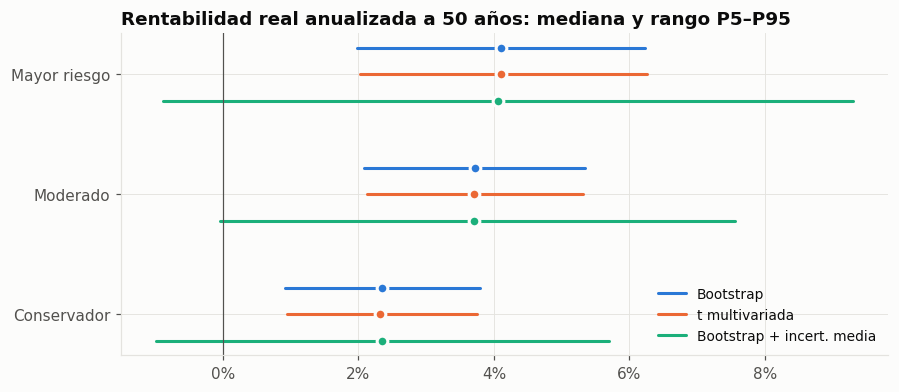

,P(mayor riesgo > conservador),P(moderado con rentabilidad real negativa)
generador,,
Bootstrap,97.4%,0.0%
t multivariada,97.4%,0.0%
Bootstrap + incert. media,79.2%,5.2%


In [6]:
fondos3 = ["mayor_riesgo", "moderado", "conservador"]
fig, ax = plt.subplots(figsize=(9, 3.8))
off = {k: d for k, d in zip(sims, (-0.22, 0, 0.22))}
for i, (k, s) in enumerate(sims.items()):
    for y, f in enumerate(fondos3):
        a = s.anualizada(s.fondo(f))
        p5, p50, p95 = np.percentile(a, [5, 50, 95])
        yy = y + off[k]
        ax.plot([p5, p95], [yy, yy], color=SERIES[i], lw=2, solid_capstyle="round", label=k if y == 0 else None)
        ax.plot([p50], [yy], "o", ms=7, color=SERIES[i], mec=SURFACE, mew=2)
ax.axvline(0, color=INK2, lw=0.8)
ax.set_yticks(range(3), [NOMBRE[f] for f in fondos3])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(pct(0))
ax.set_title("Rentabilidad real anualizada a 50 años: mediana y rango P5–P95")
ax.legend(loc="lower right", fontsize=9)
plt.show()

filas = []
for k, s in sims.items():
    mr, co = s.anualizada(s.fondo("mayor_riesgo")), s.anualizada(s.fondo("conservador"))
    filas.append({"generador": k, "P(mayor riesgo > conservador)": (mr > co).mean(),
                  "P(moderado con rentabilidad real negativa)": (s.anualizada(s.fondo("moderado")) < 0).mean()})
pd.DataFrame(filas).set_index("generador").style.format("{:.1%}")

**Lectura clave:** a 50 años, la volatilidad mensual se diversifica en el tiempo. Lo que no se diversifica es **no saber cuál es la media verdadera**. Si se toma en serio que 10 años de historia dejan un error de ~2 puntos en la media:

- el rango P5–P95 del moderado pasa de ~2–5 % a ~0–8 % real anual;
- la probabilidad de que el mayor riesgo supere al conservador baja de ~97 % a ~79 %.

Al principio, el simulador usaba la media histórica como caso base y la incertidumbre de la media solo como sensibilidad. La validación fuera de muestra (paso 8, notebook 07) mostró que sin ella el modelo es demasiado confiado, así que **el caso base del motor la activa**. Aun así es una cota superior: en la práctica, la rentabilidad esperada de largo plazo también se informa con teoría y con datos de otros mercados, no solo con estos 10 años.

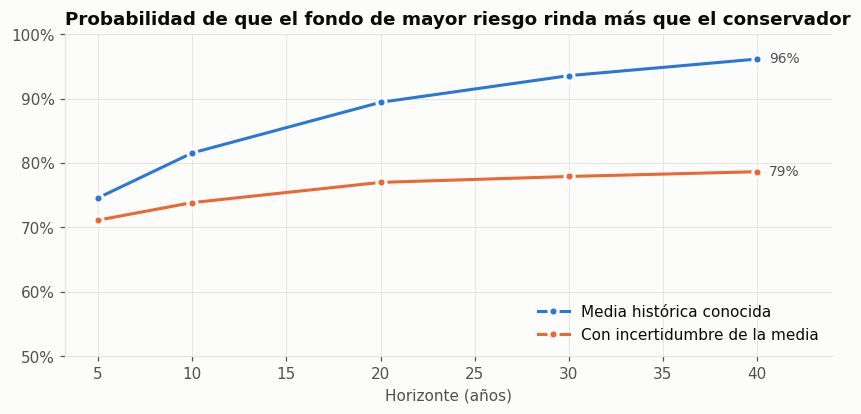

In [7]:
filas = []
for anios in (5, 10, 20, 30, 40):
    for inc in (False, True):
        s = R.bootstrap_estacionario(hist, 5_000, anios * 12, incertidumbre_media=inc, seed=SEED)
        filas.append({"anios": anios, "inc": inc,
                      "p": (s.anualizada(s.fondo("mayor_riesgo")) > s.anualizada(s.fondo("conservador"))).mean()})
h_ = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, (inc, nombre) in enumerate([(False, "Media histórica conocida"), (True, "Con incertidumbre de la media")]):
    t = h_[h_.inc == inc]
    ax.plot(t.anios, t.p, color=SERIES[i], marker="o", ms=6, mec=SURFACE, mew=2, label=nombre)
    ax.annotate(f"{t.p.iloc[-1]:.0%}", (t.anios.iloc[-1], t.p.iloc[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", color=INK2, fontsize=9)
ax.yaxis.set_major_formatter(pct(0))
ax.set_ylim(0.5, 1.0)
ax.set_xlim(right=44)
ax.set_xlabel("Horizonte (años)")
ax.set_title("Probabilidad de que el fondo de mayor riesgo rinda más que el conservador")
ax.legend(loc="lower right")
plt.show()

## 4. Escenarios deterministas (horizonte de 40 años)

In [8]:
s40 = R.bootstrap_estacionario(hist, N_SIMS, 480, seed=SEED)
esc = R.escenarios_deterministas(s40)
esc.rename(index=NOMBRE).style.format("{:.2%}").set_caption("Rentabilidad real anual constante: P10 / P50 / P90 de la simulación")

escenario,pesimista,base,optimista
Mayor riesgo,2.26%,4.11%,5.94%
Moderado,2.30%,3.71%,5.10%
Conservador,1.10%,2.34%,3.63%
Retiro programado,1.50%,2.83%,4.19%


## 5. Multifondos por defecto según la edad

Quien no elige fondo empieza en mayor riesgo, pasa gradualmente al moderado (mujeres de 42 a 46 años, hombres de 47 a 51) y converge al conservador antes de pensionarse (mujeres de 52 a 56, hombres de 57 a 61).

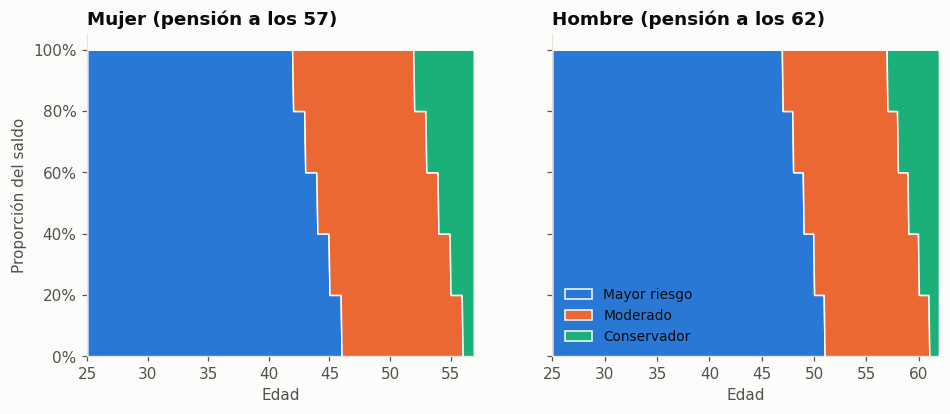

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, (sexo, edad_pen) in zip(axes, [("mujer", 57), ("hombre", 62)]):
    edades = np.arange(25 * 12, edad_pen * 12) / 12
    p = R.pesos_por_defecto(25, sexo, len(edades))
    ax.stackplot(edades, p[:, 0], p[:, 1], p[:, 2], colors=SERIES[:3], edgecolor=SURFACE, linewidth=1,
                 labels=[NOMBRE[f] for f in fondos3])
    ax.set_title(f"{sexo.capitalize()} (pensión a los {edad_pen})")
    ax.set_xlabel("Edad")
    ax.set_xlim(25, edad_pen)
    ax.grid(False)
axes[0].yaxis.set_major_formatter(pct(0))
axes[0].set_ylabel("Proporción del saldo")
axes[1].legend(loc="lower left", fontsize=9)
plt.show()

### Valor real de 1 peso invertido a los 25 años con la trayectoria por defecto (mujer)

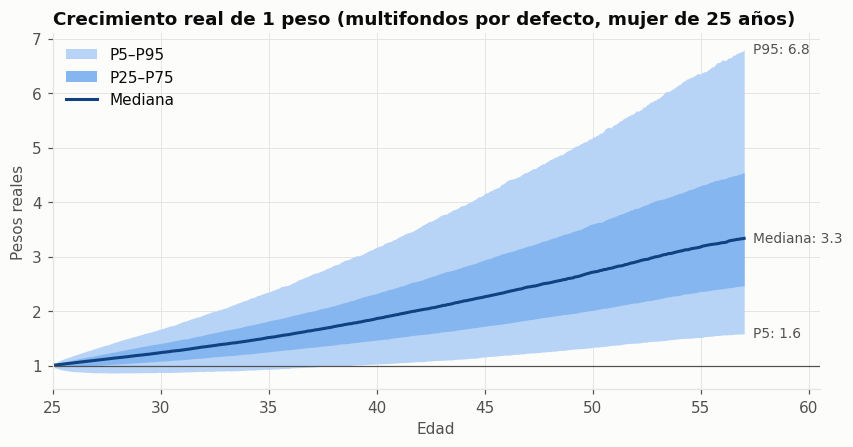

In [10]:
n = (57 - 25) * 12
s = R.bootstrap_estacionario(hist, N_SIMS, n, seed=SEED)
riqueza = np.cumprod(1 + s.portafolio(R.pesos_por_defecto(25, "mujer", n)), axis=1)
edades = 25 + np.arange(1, n + 1) / 12
q = np.percentile(riqueza, [5, 25, 50, 75, 95], axis=0)
fig, ax = plt.subplots()
ax.fill_between(edades, q[0], q[4], color=AZUL["150"], lw=0, label="P5–P95")
ax.fill_between(edades, q[1], q[3], color=AZUL["250"], lw=0, label="P25–P75")
ax.plot(edades, q[2], color=AZUL["650"], label="Mediana")
for i, lab in [(0, "P5"), (2, "Mediana"), (4, "P95")]:
    ax.annotate(f"{lab}: {q[i, -1]:.1f}", (edades[-1], q[i, -1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK2, fontsize=9)
ax.axhline(1, color=INK2, lw=0.8)
ax.set_xlim(25, 60.5)
ax.set_xlabel("Edad")
ax.set_ylabel("Pesos reales")
ax.set_title("Crecimiento real de 1 peso (multifondos por defecto, mujer de 25 años)")
ax.legend(loc="upper left")
plt.show()

## Hallazgos

1. **Los dos generadores estocásticos reproducen la historia** (media, volatilidad, correlación entre fondos). El bootstrap conserva la forma empírica de las colas; la t multivariada (ν = 4) es algo más pesimista en los meses extremos.
2. **La autocorrelación es débil** (largo de bloque óptimo de 1–2 meses) y el largo de bloque casi no cambia los resultados de largo plazo. Se usa el valor automático de Politis-White.
3. **La media es el supuesto crítico.** Con 10 años de historia su error estándar (~2 puntos por año) es mayor que la diferencia entre fondos. Con esa incertidumbre, a 50 años:
   - el rango P5–P95 del moderado se ensancha de ~2–5 % a ~0–8 % real anual;
   - la probabilidad de que el mayor riesgo le gane al conservador baja de ~97 % a ~79 %.

   El caso base del motor activa la incertidumbre de la media desde el paso 8, porque la validación fuera de muestra mostró que sin ella el modelo es demasiado confiado (notebook 07).
4. **La trayectoria por defecto de multifondos ya está implementada** según el Decreto 2555 de 2010 (arts. 2.6.11.1.5 y 2.6.11.1.6), y se usará como opción por defecto en el simulador.